## 1. Setup and data loading

This cell imports the analysis libraries, sets global plot styling, and loads the three result CSVs produced by `experiment.py`:

- `sequential_results.csv` — the single-process baseline
- `static_results.csv` — one row per (worker count, worker PID) from static scheduling
- `dynamic_results.csv` — one row per (worker count, worker PID) from dynamic scheduling

We extract the sequential wall time `t_seq` and the reference prime count `p_seq`. Every later metric is computed relative to these two numbers, so they form the anchor of the whole analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True

OUT = "data/output"
seq    = pd.read_csv(f"{OUT}/sequential_results.csv")
static = pd.read_csv(f"{OUT}/static_results.csv")
dyn    = pd.read_csv(f"{OUT}/dynamic_results.csv")

t_seq   = float(seq["wall_time"].iloc[0])
p_seq   = int(seq["total_primes"].iloc[0])
print(f"sequential: {t_seq:.3f}s   primes={p_seq:,}")
static.head()

sequential: 10.292s   primes=78,498


,pid,n_chunks,n_items,n_primes,busy_time,strategy,num_workers,wall_time,total_primes
0,8984,1,1000000,78498,8.590817,static,1,10.432266,78498
1,17176,1,500000,39185,4.529659,static,2,6.416709,78498
2,23128,1,500000,39313,4.457213,static,2,6.416709,78498
3,7484,1,250000,19415,3.265198,static,4,7.275815,78498
4,17856,1,250000,19666,3.289538,static,4,7.275815,78498


## 2. Correctness verification

Before trusting any performance number, we must confirm that the parallel implementations are **semantically identical** to the sequential baseline. Since prime counting is a *count* operation, the total number of primes found must match exactly across all runs.

If any assertion fails, the partitioning or aggregation logic has a bug and every subsequent chart is meaningless. This cell is the gate that protects the rest of the notebook.

In [2]:
assert (static["total_primes"] == p_seq).all(), "static mismatch"
assert (dyn["total_primes"]    == p_seq).all(), "dynamic mismatch"
print("✔ all runs produce identical prime count:", p_seq)

✔ all runs produce identical prime count: 78498


## 3. Per-worker load distribution

This is the **load-balancer proof** chart. For each strategy we plot each worker's total `busy_time` (the sum of its task execution times, measured *inside* the worker process — no fabrication).

- Each bar corresponds to a real OS process identified by `pid`.
- Different colors correspond to different worker counts.

**What to look for:** bars of similar height mean the load balancer spread work evenly; tall/short pairs mean imbalance. Comparing the static chart to the dynamic chart shows the effect of scheduling strategy directly.

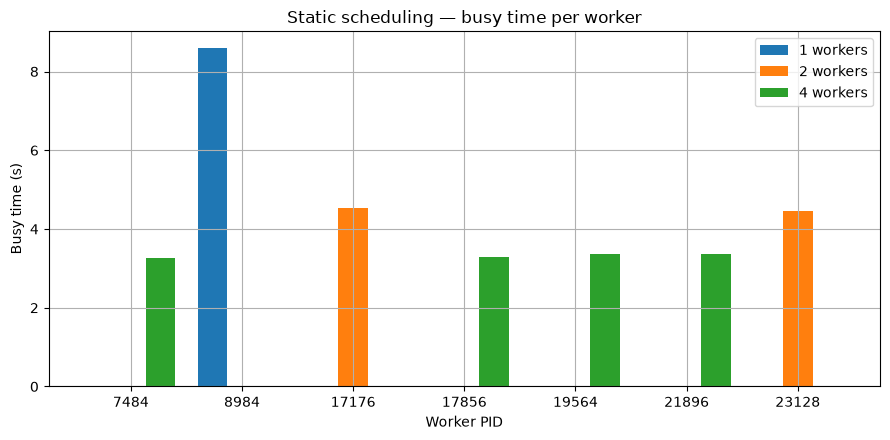

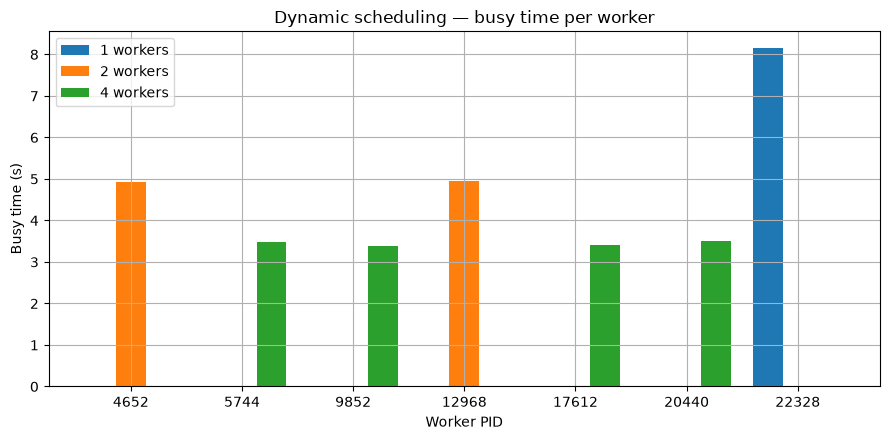

In [3]:
def per_worker_bar(strategy_df, title):
    workers = sorted(strategy_df["num_workers"].unique())
    fig, ax = plt.subplots(figsize=(9, 4.5))
    width = 0.8 / len(workers)
    pids = sorted(strategy_df["pid"].unique())
    x = np.arange(len(pids))

    for i, w in enumerate(workers):
        sub = strategy_df[strategy_df["num_workers"] == w].set_index("pid")
        busy = [sub["busy_time"].get(pid, 0) for pid in pids]
        ax.bar(x + i*width, busy, width, label=f"{w} workers")

    ax.set_xticks(x + width*(len(workers)-1)/2)
    ax.set_xticklabels(pids, rotation=0)
    ax.set_xlabel("Worker PID")
    ax.set_ylabel("Busy time (s)")
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.show()

per_worker_bar(static, "Static scheduling — busy time per worker")
per_worker_bar(dyn,    "Dynamic scheduling — busy time per worker")

## 4. Load Imbalance Ratio

The per-worker bar chart is qualitative. This cell computes the **quantitative** imbalance metric:

L = (max_busy - min_busy) / mean_busy

`L = 0` means perfectly balanced; larger values mean some workers sat idle while others did extra work. The table reports mean, min, max, and `L` for every (strategy, worker count) pair, making it easy to compare static vs. dynamic in a single glance. This is the number to cite in the report when claiming "dynamic balances better than static."

In [4]:
def imbalance(df):
    rows = []
    for (strategy, w), g in df.groupby(["strategy", "num_workers"]):
        b = g["busy_time"].values
        L = (b.max() - b.min()) / b.mean() if b.mean() > 0 else 0.0
        rows.append({"strategy": strategy, "workers": w,
                     "mean_busy": b.mean(),
                     "min_busy":  b.min(),
                     "max_busy":  b.max(),
                     "imbalance": L})
    return pd.DataFrame(rows).sort_values(["workers", "strategy"])

both = pd.concat([static, dyn])
imbalance(both).reset_index(drop=True)

,strategy,workers,mean_busy,min_busy,max_busy,imbalance
0,dynamic,1,8.148295,8.148295,8.148295,0.000000
1,static,1,8.590817,8.590817,8.590817,0.000000
2,dynamic,2,4.936905,4.915791,4.958019,0.008553
3,static,2,4.493436,4.457213,4.529659,0.016123
4,dynamic,4,3.439470,3.374163,3.503948,0.037734
5,static,4,3.320476,3.265198,3.370418,0.031688


## 5. Speedup curve

Speedup is the headline PDC metric:
S = T_sequential / T_parallel

The chart plots observed speedup for static and dynamic scheduling across worker counts, overlaid with the ideal `y = workers` line. The vertical gap between the observed lines and the ideal line is the combined cost of:

- process spawn and inter-process communication overhead (larger on Windows because it uses `spawn`, not `fork`),
- hyperthreading (4 logical cores ≠ 4 physical cores),
- the sequential fraction of each run (Amdahl's Law).

Realistic expectations: speedup will plateau below the number of logical cores, and may **regress** at high worker counts once overhead dominates. That regression is a finding, not a bug.

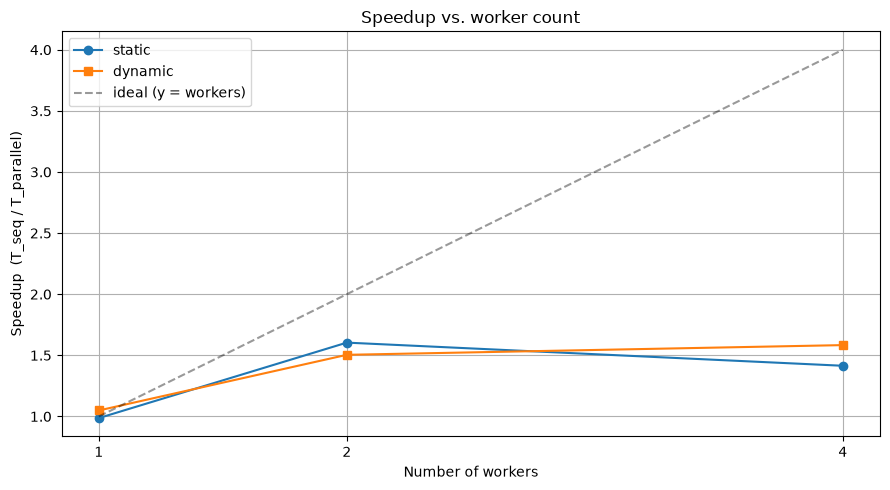

In [5]:
static_wall = static.groupby("num_workers")["wall_time"].first()
dyn_wall    = dyn.groupby("num_workers")["wall_time"].first()
workers     = sorted(static_wall.index)

su_s = [t_seq / static_wall[w] for w in workers]
su_d = [t_seq / dyn_wall[w]    for w in workers]

fig, ax = plt.subplots()
ax.plot(workers, su_s, "o-", label="static")
ax.plot(workers, su_d, "s-", label="dynamic")
ax.plot(workers, workers, "k--", alpha=0.4, label="ideal (y = workers)")
ax.set_xlabel("Number of workers")
ax.set_ylabel("Speedup  (T_seq / T_parallel)")
ax.set_title("Speedup vs. worker count")
ax.set_xticks(workers)
ax.legend()
plt.tight_layout()
plt.show()

## 6. Parallel efficiency

Speedup alone can mislead — 2× speedup on 2 workers is perfect, but 2× on 4 workers is poor. Efficiency normalizes for worker count:

E = (S / workers) × 100%


A perfect run sits on the 100% line. Any departure below it is overhead. This chart makes the trade-off between *more workers* and *per-worker usefulness* explicit, and it is the cleanest visual for the "diminishing returns" story.


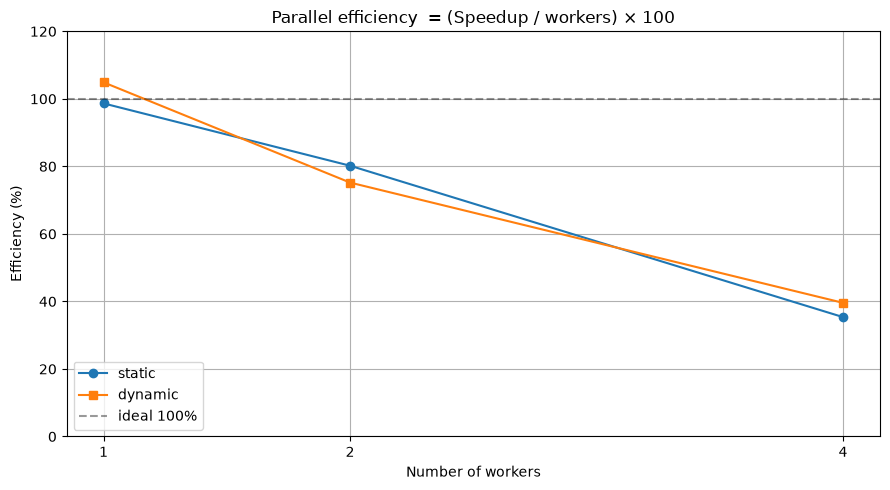

In [6]:
eff_s = [s/w for s, w in zip(su_s, workers)]
eff_d = [s/w for s, w in zip(su_d, workers)]

fig, ax = plt.subplots()
ax.plot(workers, [e*100 for e in eff_s], "o-", label="static")
ax.plot(workers, [e*100 for e in eff_d], "s-", label="dynamic")
ax.axhline(100, ls="--", color="k", alpha=0.4, label="ideal 100%")
ax.set_xlabel("Number of workers")
ax.set_ylabel("Efficiency (%)")
ax.set_title("Parallel efficiency  = (Speedup / workers) × 100")
ax.set_xticks(workers)
ax.set_ylim(0, 120)
ax.legend()
plt.tight_layout()
plt.show()

## 7. Consolidated summary

A single table collecting wall times, speedups, and efficiencies for every configuration. This is the table to copy into your report — it backs up every claim made from the charts above and gives the reader exact numbers without having to re-read three separate figures.

In [7]:
summary = pd.DataFrame({
    "workers":    workers,
    "static_s":   [static_wall[w] for w in workers],
    "dynamic_s":  [dyn_wall[w]    for w in workers],
    "speedup_s":  su_s,
    "speedup_d":  su_d,
    "eff_s_%":    [e*100 for e in eff_s],
    "eff_d_%":    [e*100 for e in eff_d],
})
summary.round(3)

,workers,static_s,dynamic_s,speedup_s,speedup_d,eff_s_%,eff_d_%
0,1,10.432,9.812,0.987,1.049,98.656,104.892
1,2,6.417,6.843,1.604,1.504,80.197,75.206
2,4,7.276,6.499,1.415,1.584,35.364,39.588
